In [ ]:
# Assignment Tasks:
# 1) Loading the Taxis Dataset using the following code:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the taxis dataset

df = sns.load_dataset("taxis")

# Display the first 5 rows

print(df.head())                                                                  # df → my DataFrame, .head() → returns the top 5 rows by default.

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [ ]:
# 2) Handling Missing Values
#●  Impute missing values using appropriate strategies based on the column type (e.g., using the mean, median, or mode for numerical columns and the mode for categorical columns).

print("Total Missing Values:", df.isnull().sum().sum())                          # True → if the value is missing (NaN), False → if the value is present.
                                                                                 # First .sum() -> Counts the True values in each column.
                                                                                 # The second .sum() -> adds all column counts together.

Total Missing Values: 186


In [ ]:
 # ● Check for missing values in the dataset and identify columns with missing data.

print("Missing Values Before Cleaning:")
print(df.isnull().sum())                                                         # count and display the number of missing values in each column of a DataFrame.

# Fill numerical columns with median                                             # df.select_dtypes()-> selects columns based on their data type.
                                                                                 # float64 → decimal numbers (e.g., fare = 12.50)
num_cols = df.select_dtypes(include=['float64', 'int64']).columns                # int64 → whole numbers (e.g., passengers = 3)
                                                                                 # .columns returns only the column names.
for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)                               # Used to replace missing values (NaN). Calculates the median of the current column.
                                                                                 # The missing value is replaced with the median.
# Fill categorical columns with mode

cat_cols = df.select_dtypes(include=['object', 'category']).columns              # Selects all text/categorical columns from the DataFrame.
                                                                                 # The loop processes each categorical column one by one.
for col in cat_cols:                                                             # The most frequently occurring value in a column.
    df[col].fillna(df[col].mode()[0], inplace=True)                              # The missing value is replaced with the most common value.
                                                                                 # For text columns, calculating: Mean, Median is not possible.
# Drop rows with missing values in critical columns

df.dropna(subset=['pickup', 'dropoff'], inplace=True)                            # dropna() removes rows that contain missing values (NaN).

# Verify results

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Missing Values Before Cleaning:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Missing Values After Cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


/tmp/ipykernel_9028/1511115417.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
/tmp/ipykernel_9028/1511115417.py:18: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

In [ ]:
# To Check

df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


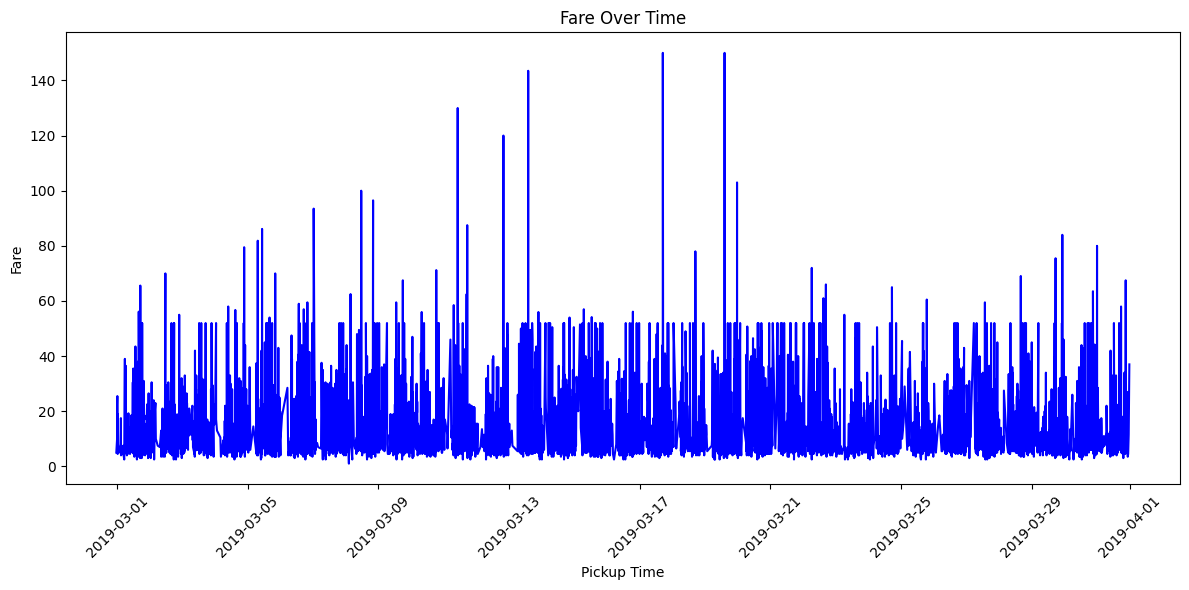

In [ ]:
# 3) Visualizations using Matplotlib/Pandas Plot:
# ★ Line Chart Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and fare as the y-axis.
# Ensure the pickup column is converted to a datetime format before plotting.

import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset

df = sns.load_dataset("taxis")

# Convert pickup column to datetime                                              # Converts the pickup column into a datetime format.
                                                                                 # Before conversion, Pandas may treat the values as plain text (strings).
df['pickup'] = pd.to_datetime(df['pickup'])                                      # After conversion, Pandas recognizes them as dates and times.

# Sort values by pickup time                                                     # This code sorts the DataFrame based on the values in the pickup column.
                                                                                 # Since pickup contains date and time information, the rows will be arranged in chronological order (earliest pickup time to latest pickup time).
df = df.sort_values('pickup')

# Plot line chart

plt.figure(figsize=(12, 6))                                                      # Creates a plotting area (canvas) with a specified size. Width = 12 inches, Height = 6 inches.
plt.plot(df['pickup'], df['fare'], color='blue')                                 # Plots a line graph. X-axis → pickup (date and time), Y-axis → fare, Line color → Blue.

plt.title('Fare Over Time')                                                      # Displays a title at the top of the chart.
plt.xlabel('Pickup Time')                                                        # Adds a label below the horizontal axis.
plt.ylabel('Fare')                                                               # Adds a label beside the vertical axis.
plt.xticks(rotation=45)                                                          # rotation -> Labels appear diagonally: making them easier to read.

plt.tight_layout()                                                               # Automatically adjusts spacing.
plt.show()                                                                       # Displays the graph on the screen.


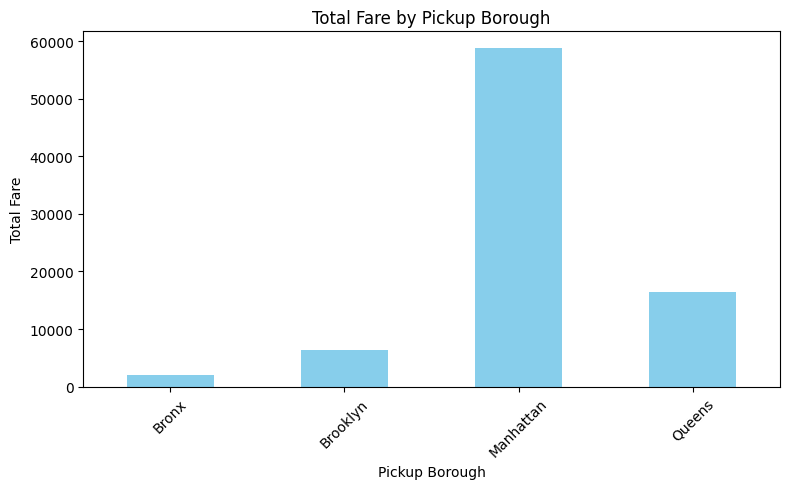

In [ ]:
# ★ Bar Chart
# Create a bar chart to show the total fare for each pickup_borough. Group the data by pickup_borough and sum the fare for each group.

import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset

df = sns.load_dataset("taxis")

# Group by pickup_borough and sum fare

borough_fare = df.groupby('pickup_borough')['fare'].sum()                        # calculates the total fare collected from each pickup borough.
                                                                                 # Groups the data based on the values in the pickup_borough column.
# Create bar chart

plt.figure(figsize=(8, 5))                                                       # Creates a plotting area. Width = 8 inches, Height = 5 inches.
borough_fare.plot(kind='bar', color='skyblue')                                   # Creates a vertical bar chart. Makes all bars light blue.

plt.title('Total Fare by Pickup Borough')                                        # Displays a title at the top.
plt.xlabel('Pickup Borough')                                                     # Adds label below the horizontal axis.
plt.ylabel('Total Fare')                                                         # Adds label beside the vertical axis.
plt.xticks(rotation=45)                                                          # rotate -> This helps when names are long and prevents overlapping.

plt.tight_layout()                                                               # Automatically adjusts spacing.
plt.show()                                                                       # Shows the completed chart on the screen.

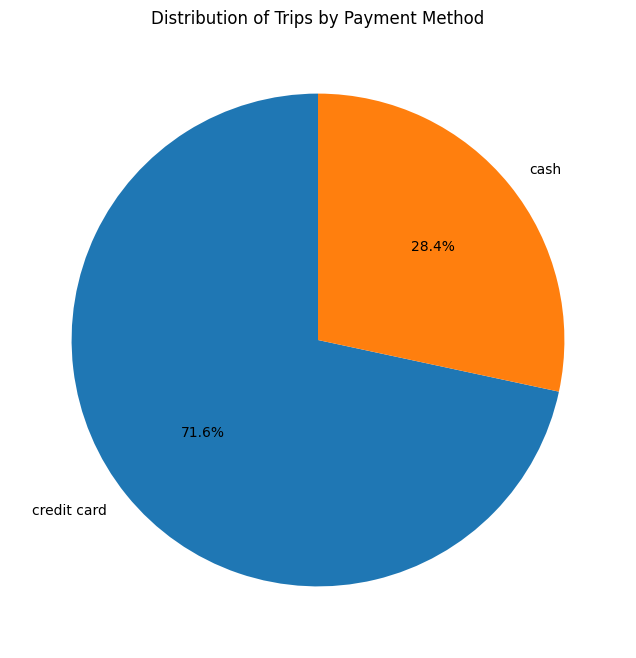

In [ ]:
# ★ Pie Chart
# Plot a pie chart showing the distribution of trips based on the payment method (credit card, cash, etc.). Each slice should represent the count of trips for a specific payment method.

import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset

df = sns.load_dataset("taxis")

# Count trips by payment method

payment_counts = df['payment'].value_counts()                                    # counts how many taxi trips were made using each payment method.

# Create pie chart

plt.figure(figsize=(8, 8))                                                       # Creates a square plotting area. Width = 8 inches, Height = 8 inches.
plt.pie(
    payment_counts,                                                              # Contains the count of trips for each payment method.
    labels=payment_counts.index,                                                 # Matplotlib uses these values to determine the slice sizes.
    autopct='%1.1f%%',                                                           # Adds names to each slice. So the pie chart labels become: Cash, Credit Card.
    startangle=90                                                                # autopct -> Displays percentages on each slice.
)                                                                                # startangle -> Controls where the first slice starts.
                                                                                 # This makes the first slice begin at the top (12 o'clock position).
plt.title('Distribution of Trips by Payment Method')                             # Add Title at the top of the chart.
plt.show()                                                                       # Shows the chart on the screen.

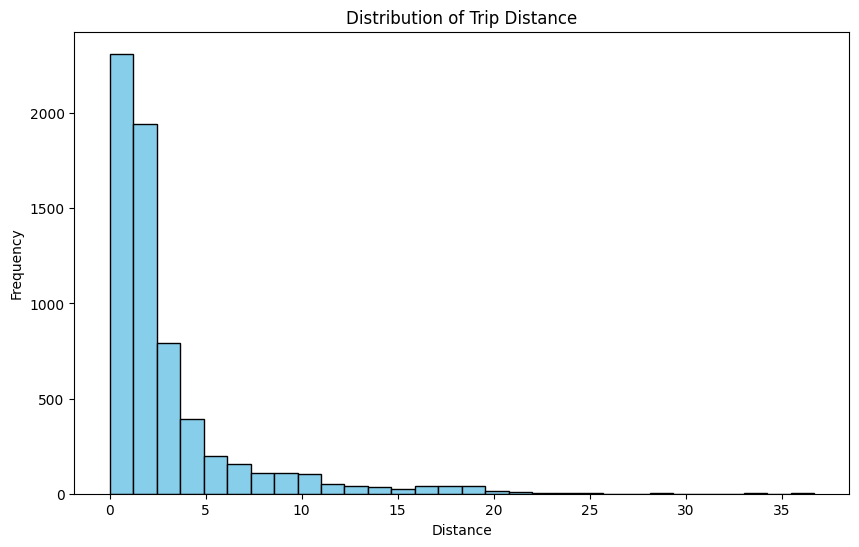

In [ ]:
# ★ Histogram
# Create a histogram to visualize the distribution of distance. Customize the number of bins for better granularity and ensure the plot is easy to interpret.

import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset

df = sns.load_dataset("taxis")

# Create histogram                                                               # Histogram to visualize the distribution of taxi trip distances.

plt.figure(figsize=(10, 6))                                                      # Creates the plotting area. Width = 10 inches, Height = 6 inches.
plt.hist(df['distance'], bins=30, color='skyblue', edgecolor='black')            # Uses the distance column as input. A histogram groups data into intervals called bins. Divide the distance values into 30 intervals.
                                                                                 # Makes all bars light blue. Adds black borders around each bar. This makes bars easier to distinguish.
plt.title('Distribution of Trip Distance')                                       # Add Title at the top of the chart.
plt.xlabel('Distance')                                                           # X-axis = Trip Distance
plt.ylabel('Frequency')                                                          # Y-Axis = Frequency means: Number of trips

plt.show()                                                                       # Shows the histogram.

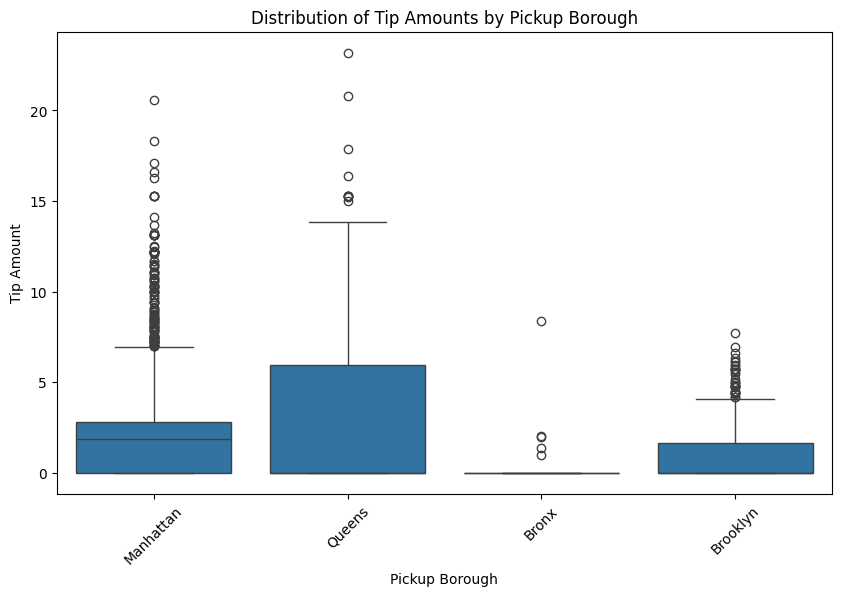

In [ ]:
# ★ Box Plot
# Plot a box plot to visualize the distribution of tip amounts for each pickup_borough. Use pickup_borough as the categorical axis and tip as the numeric axis.

import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset

df = sns.load_dataset("taxis")

# Create box plot                                                                # creates a Box Plot to compare the distribution of tip amounts across different pickup boroughs.

plt.figure(figsize=(10, 6))                                                      # Creates a plotting area. Width = 10 inches, Height = 6 inches

sns.boxplot(
    x='pickup_borough',                                                          # Places boroughs on the X-axis.
    y='tip',                                                                     # Places tip amounts on the Y-axis.
    data=df                                                                      # Uses the dataframe df as the data source.
)

plt.title('Distribution of Tip Amounts by Pickup Borough')                       # Add Title
plt.xlabel('Pickup Borough')                                                     # Label X-Axis
plt.ylabel('Tip Amount')                                                         # Label Y-Axis

plt.xticks(rotation=45)                                                          # it may overlap. After rotation, labels are easier to read.
plt.show()                                                                       # Shows the chart.

/tmp/ipykernel_9028/1688777777.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


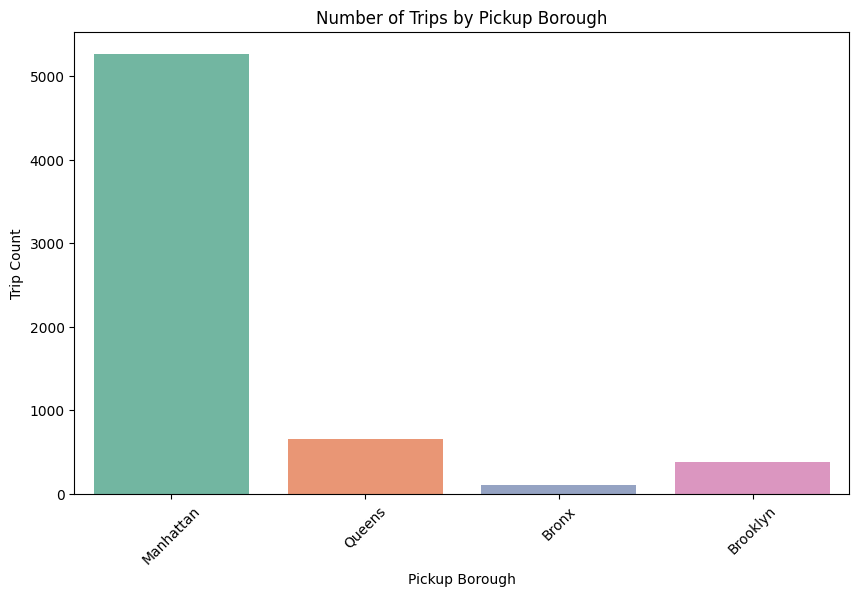

In [ ]:
# Visualizations using Seaborn:
# ★ Count Plot
# Create a count plot to visualize the number of trips in each pickup_borough. The x-axis should represent the boroughs, and the y-axis should show the count of trips.

import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset

df = sns.load_dataset("taxis")

# Create count plot                                                              # Count Plot shows the number of occurrences of each category in a column.

plt.figure(figsize=(10, 6))                                                      # plt refers to Matplotlib's pyplot module. figure() creates a new plotting area (canvas).
                                                                                 # figsize=(10, 6) sets the size of the figure: Width = 10 inches, Height = 6 inches
sns.countplot(
    x='pickup_borough',                                                          # x='pickup_borough' -> Borough names (Manhattan, Queens, Brooklyn, etc.) appear on the X-axis.
    data=df,                                                                     # Tells Seaborn to use the DataFrame df.
    palette='Set2'                                                               # Applies the Set2 color palette. Gives each bar a different soft color to improve visualization.
)

plt.title('Number of Trips by Pickup Borough')                                   # Adds a title at the top of the chart.
plt.xlabel('Pickup Borough')                                                     # Names the X-axis.
plt.ylabel('Trip Count')                                                         # Names the Y-axis.

plt.xticks(rotation=45)                                                          # Prevents labels from overlapping if they are long.
plt.show()                                                                       # displays the chart.


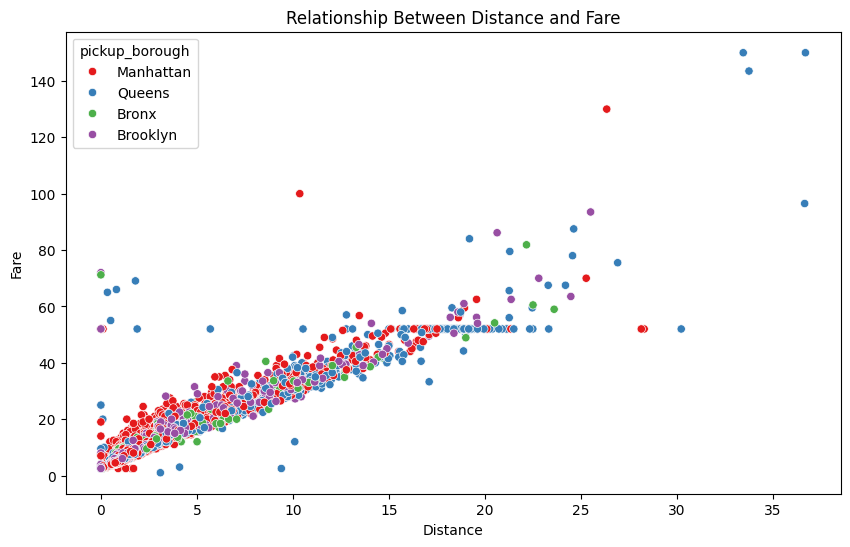

In [ ]:
# ★ Scatter Plot
# Plot a scatter plot to show the relationship between distance and fare. Use distance on the x-axis and fare on the y-axis to visualize any correlation. Color the points based on the pickup_borough to differentiate the trips by their respective boroughs.

import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset

df = sns.load_dataset("taxis")

# Create scatter plot                                                            # Scatter Plot to visualize the relationship between the distance traveled and the fare charged for taxi trips.

plt.figure(figsize=(10, 6))                                                      # Sets the figure size to 10 inches wide and 6 inches high.

sns.scatterplot(                                                                 # A scatter plot displays the relationship between two numerical variables. Each dot represents one taxi trip.
    data=df,                                                                     # Uses the taxi dataset stored in DataFrame df.
    x='distance',                                                                # Distance is shown on the X-axis.
    y='fare',                                                                    # Fare is shown on the Y-axis.
    hue='pickup_borough',                                                        # Colors the dots based on the pickup borough. Trips from different boroughs get different colors.
    palette='Set1'                                                               # Applies the Set1 color palette to make boroughs visually distinct.
)

plt.title('Relationship Between Distance and Fare')                              # Displays the title
plt.xlabel('Distance')                                                           # Labels the X-axis as Distance.
plt.ylabel('Fare')                                                               # Labels the Y-axis as Fare.

plt.show()                                                                       # Shows the completed scatter plot.

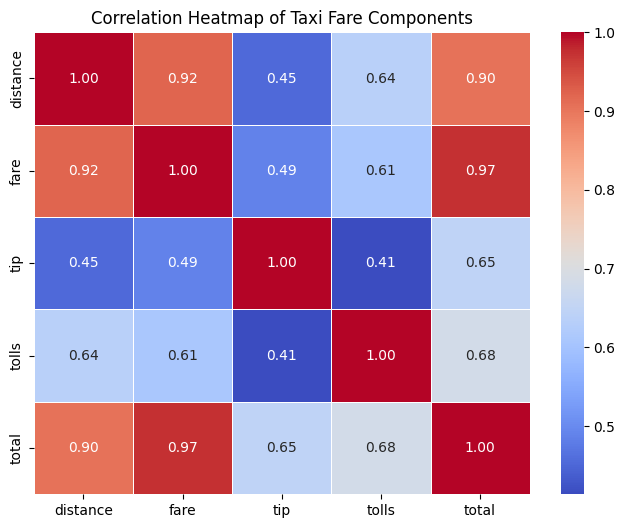

In [ ]:
# ★ Heatmap
# Plot a heatmap to visualize the correlation between numerical variables such as distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the relationships.

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns                                                       # Correlation Heatmap that shows the strength and direction of relationships between numerical variables in the taxi dataset.

corr_cols = ['distance', 'fare', 'tip', 'tolls', 'total']                        # Only numerical columns can be used to calculate correlation.

# Calculate correlation matrix

corr_matrix = df[corr_cols].corr()                                               # .corr() function calculates the Pearson Correlation Coefficient between every pair of columns.

# Create heatmap

plt.figure(figsize=(8, 6))                                                       # Creates a plotting area with: Width = 8 inches, Height = 6 inches.
sns.heatmap(
    corr_matrix,                                                                 # Uses the correlation matrix as input.
    annot=True,                                                                  # Displays correlation values inside each cell.
    cmap='coolwarm',                                                             # Sets the color scheme
    fmt='.2f',                                                                   # Formats values to 2 decimal places.
    linewidths=0.5                                                               # Adds thin lines between cells.
)

plt.title('Correlation Heatmap of Taxi Fare Components')                         # Displays the title.
plt.show()                                                                       # Shows the heatmap.

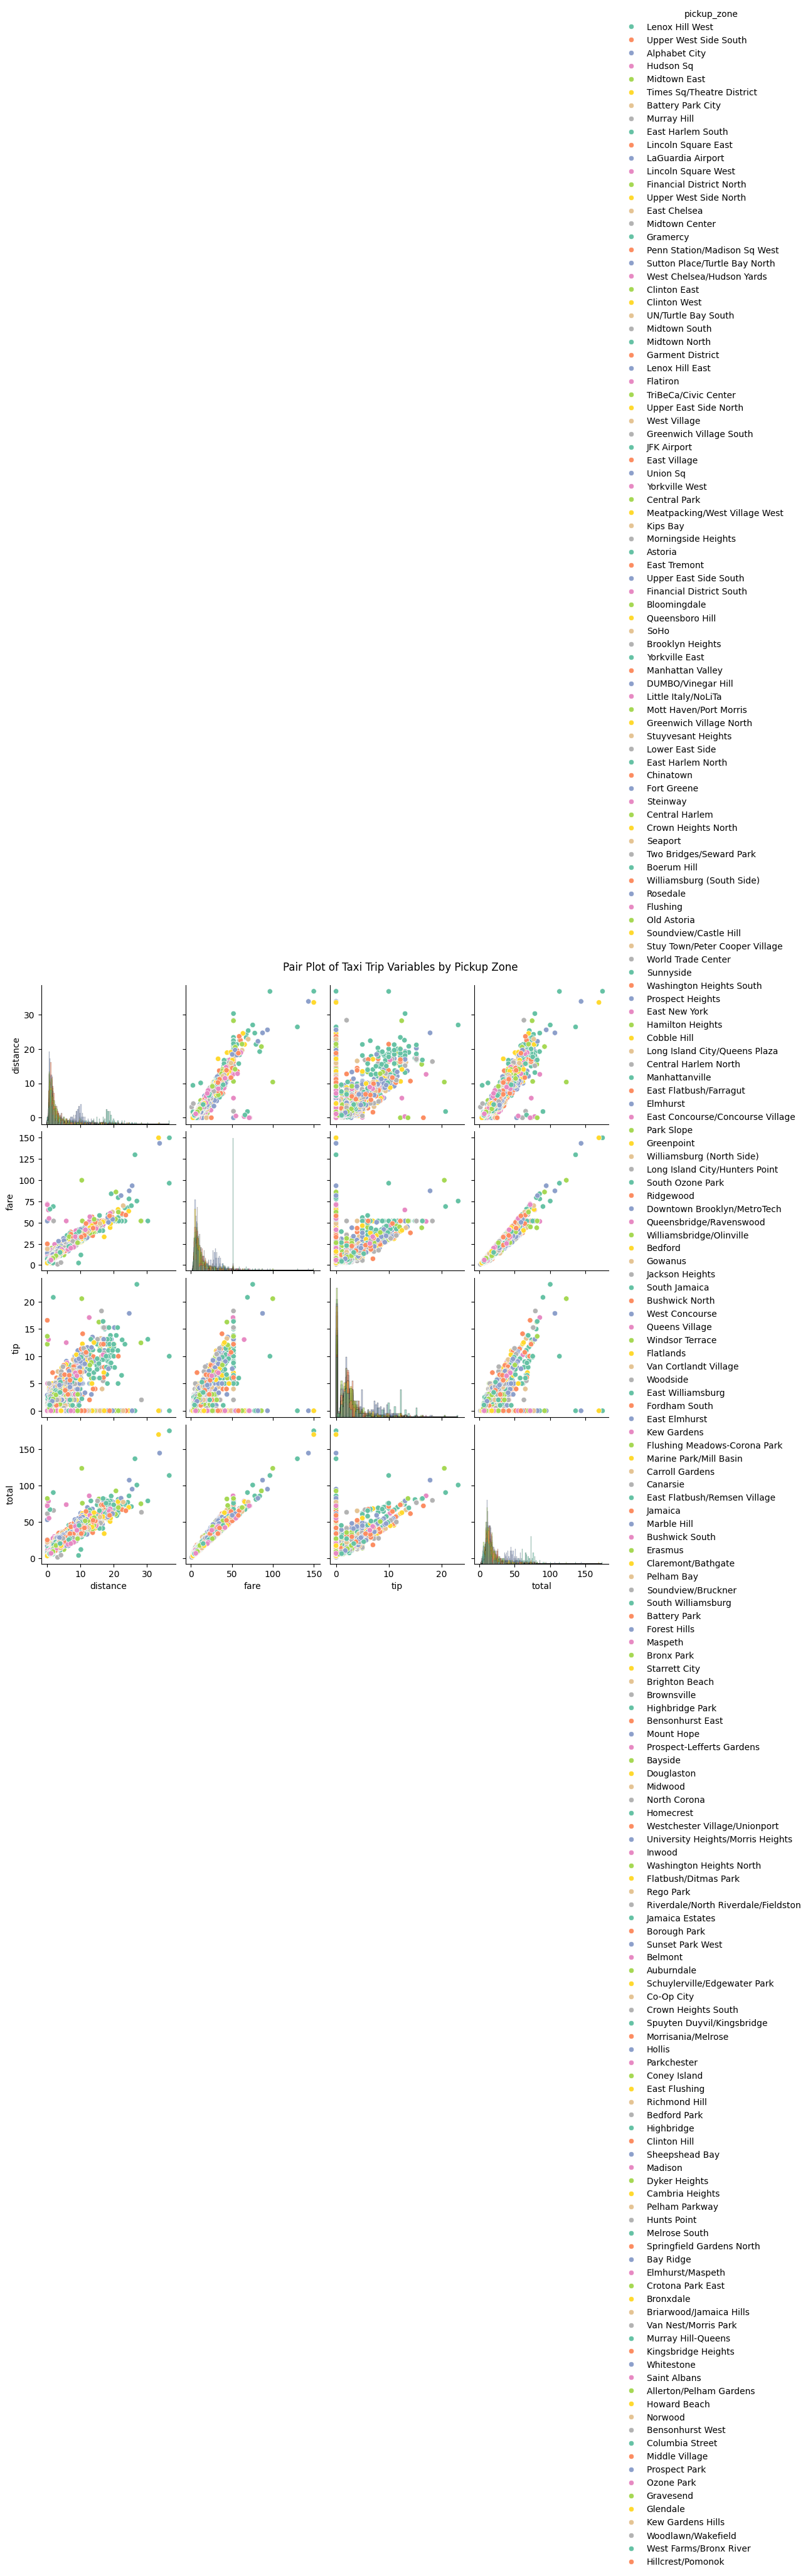

In [ ]:
# ★ Pair Plot
# Create a pair plot to visualize the pairwise relationships between distance, fare, tip, and total. Color the data points according to the pickup_zone column. to compare how different zones affect these variables.

import seaborn as sns
import matplotlib.pyplot as plt

# Select required columns and remove missing values

pair_data = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna()     # Removes rows containing missing values.

# Create pair plot                                                               # helps analyze relationships between multiple numerical variables at the same time.

sns.pairplot(
    pair_data,
    vars=['distance', 'fare', 'tip', 'total'],                                   # numerical variables to compare.
    hue='pickup_zone',                                                           # Colors points according to the pickup zone.
    diag_kind='hist',                                                            # Displays histograms on the diagonal. Shows whether most fares are low, medium, or high.
    palette='Set2'                                                               # Applies a soft color theme for the pickup zones.
)

plt.suptitle('Pair Plot of Taxi Trip Variables by Pickup Zone', y=1.02)          # Add Title. y=1.02 -> Moves the title slightly upward to avoid overlapping with the plots.
plt.show()                                                                       # Displays the pair plot.

/tmp/ipykernel_583/1443482386.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


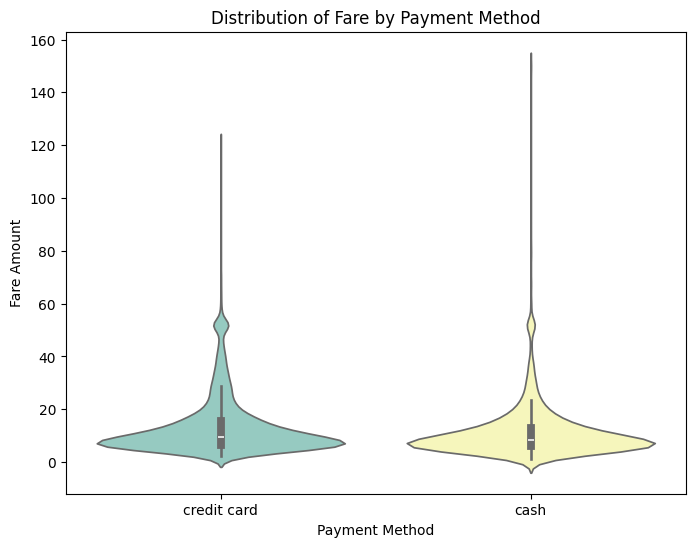

In [ ]:
# ★ Violin Plot
# Plot a violin plot to show the distribution of fare for each payment method. Use the payment method as the categorical axis and fare as the numeric axis to visualize its distribution.

import seaborn as sns
import matplotlib.pyplot as plt

# Remove missing values

violin_data = df[['payment', 'fare']].dropna()                                   # Removes rows containing missing values.

# Create violin plot                                                             # Violin Plot to visualize how taxi fare amounts are distributed across different payment methods.

plt.figure(figsize=(8, 6))                                                       # Creates Figure.
sns.violinplot(
    data=violin_data,
    x='payment',                                                                 # Places payment methods on the X-axis.
    y='fare',                                                                    # Places fare amounts on the Y-axis.
    palette='Set3'                                                               # Applies a colorful palette to distinguish payment methods.
)                                                                                # Wider sections = more trips at that fare range, Wider sections = more trips at that fare range.

plt.title('Distribution of Fare by Payment Method')                              # Displays Title
plt.xlabel('Payment Method')                                                     # Labels x-axis as Payment Method
plt.ylabel('Fare Amount')                                                        # Labels y-axis as Fare Amount
plt.show()                                                                       # Shows Violin Plot.